In [16]:
from datetime import datetime, timedelta, timezone
import pandas as pd
import requests
import os
os.environ["KERAS_BACKEND"] = "torch"
import keras
from pathlib import Path
import joblib
import keras
from keras import layers
import openmeteo_requests
import requests_cache
from retry_requests import retry
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.metrics import mean_squared_error, mean_absolute_error

PROJECT_ROOT = Path.cwd().parents[1]
MODEL_DIR = PROJECT_ROOT / "models"

In [2]:
lag, horizon, batch = 24, 24, 128

features =  ['Demand', 'temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'wind_speed_10m', 'surface_pressure', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'month_sin', 'month_cos', 'is_weekend']
features_to_scale = ['temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'wind_speed_10m', 'surface_pressure']
targets = ['Demand']

In [ ]:
## Functions
def fetch_EIA_data(start_date):
	API_KEY = "2INKygIhcpBYvgctY2q8KLlIOGthBWTykYIKnYF4"
	url = "https://api.eia.gov/v2/electricity/rto/region-data/data/"
	now = datetime.now(timezone.utc)
	end_date = now.strftime("%Y-%m-%dT%H")
	base_params = [
	("api_key", API_KEY),
	("frequency", "hourly"),
	("data[0]", "value"),
	("facets[respondent][]", "NY"),
	("start", start_date),
	("end", end_date),
	("sort[0][column]", "period"),
	("sort[0][direction]", "asc")
		]

	all_rows = []
	offset = 0
	page_size = 5000
	total = None
	
	while total is None or offset < total:
		params = base_params + [
			("offset", offset),
			("length", page_size)
		]
		response = requests.get(url, params=params)
		response.raise_for_status()
		result = response.json()["response"]
		rows = result["data"]

		if total is None:
			total = int(result["total"])
			print(f"Total rows available: {total}")

		if not rows:
			break

		all_rows.extend(rows)
		offset += len(rows)

	df = pd.DataFrame(all_rows)
	df["value"] = pd.to_numeric(df["value"])
	df = df.pivot(index=["period", "respondent", "respondent-name"], columns="type-name", values="value").reset_index()
	df.columns.name = None
	df = df.drop(columns=["respondent-name"])
	df = df.rename(columns={"period": "Time"})
	df["Time"] = pd.to_datetime(df["Time"], format="%Y-%m-%dT%H")
	return df

def get_weather_data(start_date):
	now = datetime.now(timezone.utc)
	end_date = now.strftime("%Y-%m-%dT%H:00")
	params = {
		"latitude": 40.7128,
		"longitude": -74.0060,
		"start_hour": start_date,
		"end_hour": end_date,
		"hourly": ["temperature_2m", "relative_humidity_2m", "apparent_temperature", "precipitation", "wind_speed_10m", "surface_pressure"],
	}
	cache_session = requests_cache.CachedSession('.cache', expire_after = 3600)
	retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
	openmeteo = openmeteo_requests.Client(session = retry_session)

	url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

	responses = openmeteo.weather_api(url, params = params)

	# Process first location. Add a for-loop for multiple locations or weather models
	response = responses[0]
	print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
	print(f"Elevation: {response.Elevation()} m asl")
	print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

	# Process hourly data. The order of variables needs to be the same as requested.
	hourly = response.Hourly()
	hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
	hourly_relative_humidity_2m = hourly.Variables(1).ValuesAsNumpy()
	hourly_apparent_temperature = hourly.Variables(2).ValuesAsNumpy()
	hourly_precipitation = hourly.Variables(3).ValuesAsNumpy()
	hourly_wind_speed_10m = hourly.Variables(4).ValuesAsNumpy()
	hourly_surface_pressure = hourly.Variables(5).ValuesAsNumpy()

	hourly_data = {
		"date": pd.date_range(
			start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
			end =  pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
			freq = pd.Timedelta(seconds = hourly.Interval()),
			inclusive = "left"
		)
	}

	hourly_data["temperature_2m"] = hourly_temperature_2m
	hourly_data["relative_humidity_2m"] = hourly_relative_humidity_2m
	hourly_data["apparent_temperature"] = hourly_apparent_temperature
	hourly_data["precipitation"] = hourly_precipitation
	hourly_data["wind_speed_10m"] = hourly_wind_speed_10m
	hourly_data["surface_pressure"] = hourly_surface_pressure

	df = pd.DataFrame(data = hourly_data)
	df = df.rename(columns={"date": "Time"})
	df["Time"] = pd.to_datetime(df["Time"])
	df["Time"] = df["Time"].dt.tz_localize(None)
	return df

def make_features(df):
	df["hour_sin"] = np.sin(2 * np.pi * df["Time"].dt.hour / 24)
	df["hour_cos"] = np.cos(2 * np.pi * df["Time"].dt.hour / 24)
	df["day_sin"] = np.sin(2 * np.pi * df["Time"].dt.dayofweek / 7)
	df["day_cos"] = np.cos(2 * np.pi * df["Time"].dt.dayofweek / 7)
	df["month_sin"] = np.sin(2 * np.pi * df["Time"].dt.month / 12)
	df["month_cos"] = np.cos(2 * np.pi * df["Time"].dt.month / 12)
	df["is_weekend"] = (df["Time"].dt.dayofweek > 4).astype(int)
	df["lag1"] = df["Demand"].shift(1)
	df["lag24"] = df["Demand"].shift(24)
	df["lag48"] = df["Demand"].shift(48)
	df["lag168"] = df["Demand"].shift(168)
	df["rolling_mean24"] = df["Demand"].rolling(window=24).mean()
	df["rolling_std24"] = df["Demand"].rolling(window=24).std()
	return df

def make_ds(arr, shuffle):
	target_column = arr[:, 0]
	y = np.lib.stride_tricks.sliding_window_view(target_column, window_shape=horizon)
	y = y[lag:]
	X = arr[:len(y)]
	return keras.utils.timeseries_dataset_from_array(data=X, targets=y, sequence_length=lag, batch_size=batch, shuffle=shuffle)

def plot_acf_graph(data):
	hours_window = 192
	fig, ax = plt.subplots(figsize=(26, 5))
	plot_acf(data["Demand"], lags=hours_window, ax=ax)
	plt.xlabel("Lag (Hours)")
	plt.ylabel("Autocorrelation")
	plt.grid(True, alpha=0.5)
	plt.ylim(bottom=0, top=1.1)
	plt.xticks(ticks=range(0,hours_window + 1, 2), rotation=90)
	plt.yticks(ticks=np.arange(0.0, 1.1, 0.1))
	plt.show()

def prep_data(energy, weather):
	merged_df = pd.merge(energy, weather, on="Time", how="inner")
	data = make_features(merged_df)
	plot_acf_graph(data)
	
	n = len(data)
	train_end = int(n*0.80)
	val_end = int(n*0.90)
	scaler = StandardScaler()

	train_data = data.iloc[:train_end][features].copy()
	val_data = data.iloc[train_end: val_end][features].copy()
	test_data = data.iloc[val_end:][features].copy()

	target_scaler = StandardScaler()
	feats_scaler = StandardScaler()

	train_data["Demand"] = target_scaler.fit_transform(train_data[["Demand"]])
	val_data["Demand"] = target_scaler.transform(val_data[["Demand"]])


	train_data[features_to_scale] = feats_scaler.fit_transform(train_data[features_to_scale])
	val_data[features_to_scale] = feats_scaler.transform(val_data[features_to_scale])

	train_data_scaled = train_data.values
	val_data_scaled = val_data.values

	joblib.dump(target_scaler, MODEL_DIR / f'target_scaler_lag_{lag}_h_{horizon}_b_{batch}.pkl')
	joblib.dump(feats_scaler, MODEL_DIR / f'feats_scaler_lag_{lag}_h_{horizon}_b_{batch}.pkl')

	train_ds = make_ds(train_data_scaled, shuffle=True)
	val_ds = make_ds(val_data_scaled, shuffle=False)

	return train_ds, val_ds, test_data
	
def train_model(train_ds, val_ds):
	model = keras.Sequential([
	layers.Input(shape=(lag, len(features))),
	layers.LSTM(64, return_sequences=False),
	layers.Dense(64, activation="relu", use_bias=True),
	layers.Dropout(0.3),
	layers.Dense(32, activation="relu", use_bias=True),
	layers.Dense(horizon, use_bias=True)
		])
	model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="mae", metrics=["mae"])
	callbacks = [
		keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True),
		keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2),
		keras.callbacks.ModelCheckpoint("best_lstm.keras", save_best_only=True)
	]
	history = model.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks)
	model.save(MODEL_DIR / f"model_lag_{lag}_h_{horizon}_b_{batch}.keras")

	return history

def plot_history(history):
	loss = history.history["loss"]
	val_loss = history.history["val_loss"]
	epochs = range(1, len(loss) + 1)

	fig, ax = plt.subplots(figsize=(8, 5))
	ax.plot(epochs, loss, "bo-", label="Training Loss")
	ax.plot(epochs, val_loss, "ro-", label="Validation Loss")
	ax.set_title("Losses during Training")
	ax.set_xlabel("Epochs")
	ax.set_ylabel("Loss")
	ax.grid(True, alpha=0.5)
	ax.set_xticks(ticks=range(1, len(loss) + 1))
	ax.legend()
	plt.tight_layout()
	plt.show()

def plot_forecast(test_data, index):

	target_scaler = joblib.load(MODEL_DIR / f'target_scaler_lag_{lag}_h_{horizon}_b_{batch}.pkl')
	feats_scaler = joblib.load(MODEL_DIR / f'feats_scaler_lag_{lag}_h_{horizon}_b_{batch}.pkl')
	model = keras.models.load_model(MODEL_DIR / f'model_lag_{lag}_h_{horizon}_b_{batch}.keras')

	idx = index
	window = test_data[features].iloc[idx :lag + idx].copy()
	window.to_csv(PROJECT_ROOT / "dashboard" / "utils" / "trial_data.csv", index=False)
	window[features_to_scale] = feats_scaler.transform(window[features_to_scale])
	window["Demand"] = target_scaler.transform(window[["Demand"]])
	x = window.values[None, :, :]

	pred_scaled = model.predict(x)
	pred = target_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
	test_arr = test_data[features].values
	fig, ax = plt.subplots(figsize=(18, 5))
	ax.plot(np.arange(0, lag + 1), test_arr[idx : idx + lag + 1, 0], label="Input Steps")
	ax.plot(np.arange(lag, lag + horizon), test_arr[idx + lag: idx + lag + horizon, 0], label="True Future Steps")
	ax.plot(np.arange(lag, lag + horizon), pred, label="Predicted Steps")
	ax.set_xlabel("Hours")
	ax.set_ylabel("Energy Demand (MW)")
	ax.set_title(f"LSTM Performance at index {idx}")
	ax.set_xticks(ticks=np.arange(0, lag + horizon, horizon))
	ax.grid(True, alpha=0.5)
	ax.set_xlim(left=0)
	ax.legend()
	plt.tight_layout()
	plt.show()

	print(f"MAE: {mean_absolute_error(test_arr[idx + lag: idx + lag + horizon, 0], pred)}")
	print(f"RMSE: {np.sqrt(mean_squared_error(test_arr[idx + lag: idx + lag + horizon, 0], pred))}")


In [28]:
def make_forecast():
	target_scaler = joblib.load(MODEL_DIR / f'target_scaler_lag_{lag}_h_{horizon}_b_{batch}.pkl')
	feats_scaler = joblib.load(MODEL_DIR / f'feats_scaler_lag_{lag}_h_{horizon}_b_{batch}.pkl')
	model = keras.models.load_model(MODEL_DIR / f'model_lag_{lag}_h_{horizon}_b_{batch}.keras')
	trial_data = pd.read_csv(PROJECT_ROOT / "dashboard" / "utils" / "trial_data.csv")
	plot_data = trial_data.copy()
	trial_data[features_to_scale] = feats_scaler.transform(trial_data[features_to_scale])
	trial_data["Demand"] = target_scaler.transform(trial_data[["Demand"]])
	x = trial_data[features].values[None, :, :]
	pred_scaled = model.predict(x)
	pred = target_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
	fig = go.Figure()
	fig.add_trace(go.Scatter(
		x=np.arange(0, lag),
		y=plot_data["Demand"]
	))
	fig.add_trace(go.Scatter(
		x=np.arange(lag, lag + horizon),
		y=pred
	))
	fig.show()


In [6]:
start_date = "2022-01-01"
energy = fetch_EIA_data(start_date)
weather = get_weather_data(start_date)

Total rows available: 170047
Coordinates: 40.71033477783203°N -73.99308013916016°E
Elevation: 32.0 m asl
Timezone difference to GMT+0: 0s


C:\Users\nippu\AppData\Local\Temp\ipykernel_17588\1930957430.py:89: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  freq = pd.Timedelta(seconds = hourly.Interval()),


TypeError: plot_acf() got an unexpected keyword argument 'lags'

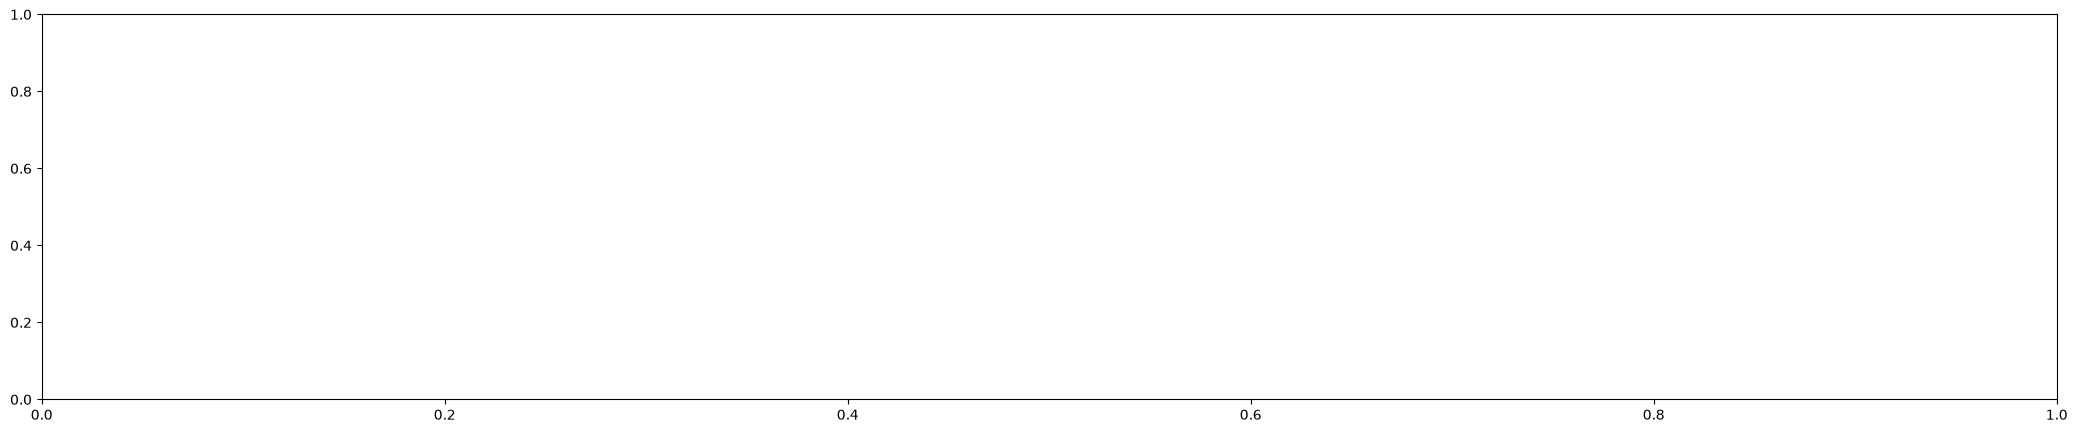

In [15]:
train_ds, val_ds, test_data = prep_data(energy, weather)

In [ ]:
history = train_model(train_ds, val_ds)


Epoch 1/50


C:\Users\nippu\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


266/266 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.4143 - mae: 0.4143 - val_loss: 0.2860 - val_mae: 0.2860 - learning_rate: 0.0010
Epoch 2/50
266/266 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.2695 - mae: 0.2695 - val_loss: 0.2690 - val_mae: 0.2690 - learning_rate: 0.0010
Epoch 3/50
266/266 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.2533 - mae: 0.2533 - val_loss: 0.2561 - val_mae: 0.2561 - learning_rate: 0.0010
Epoch 4/50
266/266 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.2431 - mae: 0.2431 - val_loss: 0.2512 - val_mae: 0.2512 - learning_rate: 0.0010
Epoch 5/50
266/266 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.2351 - mae: 0.2351 - val_loss: 0.2507 - val_mae: 0.2507 - learning_rate: 0.0010
Epoch 6/50
266/266 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.2304 - mae: 0.2304 - val_loss: 0.2415 - val_mae: 0.2415 - learning_rate: 0.0010
Epoch 7/50
266/266 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.2250 - mae: 0.2250 - val_loss: 0.2452 - val_mae: 0.2452 - learning_rate: 0.0010
Epoch 8/50

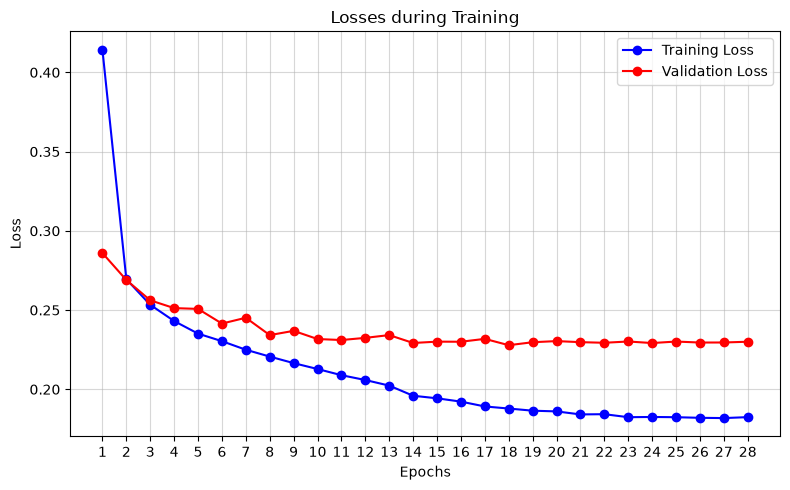

In [12]:
plot_history(history)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


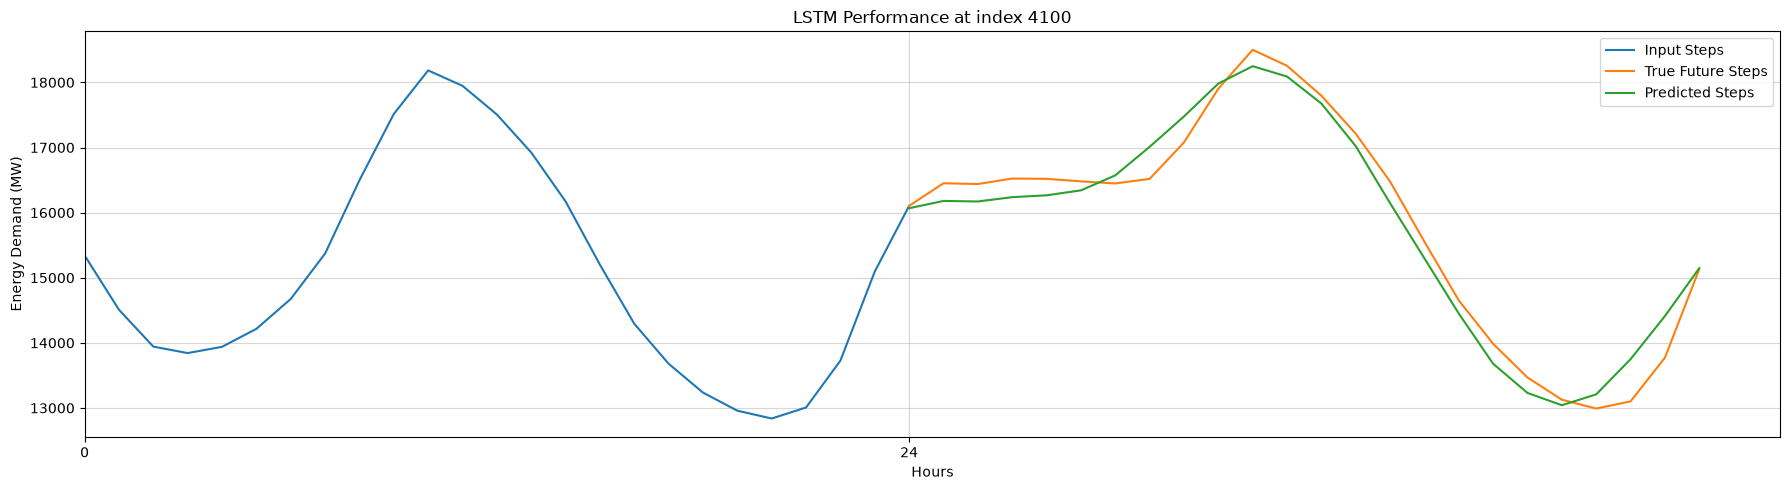

MAE: 250.67899576822916
RMSE: 297.74325818540143


In [13]:
plot_forecast(test_data, index=4100)